#Introducere în Machine Learning


###Laboratorul 1

 Sarcini practice bazate pe setul de date Iris.csv

- Pandas https://pandas.pydata.org/docs/,
- Matplotlib https://matplotlib.org/,
- Seaborn https://seaborn.pydata.org/,
- Intel Extension for Scikit-learn https://uxlfoundation.github.io/scikit-learn-intelex/latest/index.html

### Pregătire (Google Colab)
Rulați celula de mai jos: dacă fișierul `Iris_Data.csv` nu există în sesiune, se va deschide fereastra de încărcare.

In [1]:
import os
FILE = 'Iris_Data.csv'
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()          # alegeți Iris_Data.csv
    except ImportError:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Exercițiul 1: Încărcarea și analiza inițială a datelor

Folosind bibliotecile pandas și numpy, încărcați fișierul Iris_Data.csv din directorul data. Afișați pe ecran:
 - Numărul total de rânduri.
 - Numele tuturor coloanelor.
 - Tipurile de date pentru fiecare coloană.

In [2]:
data = pd.read_csv(FILE)

print('Numărul total de rânduri:', data.shape[0])
print('Numele coloanelor:', data.columns.tolist())
print('\nTipurile de date:')
print(data.dtypes)
data.head()

Numărul total de rânduri: 150
Numele coloanelor: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Tipurile de date:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


###Exercițiul 2: Curățarea și transformarea datelor text

Explorați valorile din coloana species.
Observați că toate încep cu prefixul Iris-.

Scrieți cod pentru a elimina acest prefix din toate rândurile (astfel încât să rămână doar setosa, versicolor, virginica).

In [3]:
print('Înainte:', data['species'].unique())

data['species'] = data['species'].str.replace('Iris-', '', regex=False)

print('După:  ', data['species'].unique())
data.head()

Înainte: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str
După:   <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Exercițiul 3: Statistica descriptivă și amplitudinea (range)

Folosind metoda describe()creați un rând nou în tabel numit range, care calculează diferența dintre valoarea maximă și valoarea minimă pentru fiecare coloană numerică.

In [4]:
stats_df = data.describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

# rânduri afișate într-o ordine logică
stats_df = stats_df.loc[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'range']]
stats_df

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000
range,3.600000,2.400000,5.900000,2.400000


### Exercițiul 4: Grupatarea datelor pe specii (Media și Mediana)
 Grupați setul de date după coloana species  și aplicați simultan funcțiile de medie (mean)și mediană (median) pentru toate coloanele numerice.

In [5]:
data.groupby('species').agg(['mean', 'median'])

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

### Exercițiul 5: Agregare avansată utilizând un dicționar

Folosind metoda agg() pentru datele grupate
aplicați următoarele reguli: pentru sepal_length, sepal_width și petal_width calculați media și mediana, iar pentru petal_length — doar valoarea maximă (max).

In [6]:
agg_dict = {
    'sepal_length': ['mean', 'median'],
    'sepal_width':  ['mean', 'median'],
    'petal_length': ['max'],
    'petal_width':  ['mean', 'median'],
}
data.groupby('species').agg(agg_dict)

sepal_length        sepal_width        petal_length petal_width  \
                   mean median        mean median          max        mean   
species                                                                      
setosa            5.006    5.0       3.418    3.4          1.9       0.244   
versicolor        5.936    5.9       2.770    2.8          5.1       1.326   
virginica         6.588    6.5       2.974    3.0          6.9       2.026   

                   
           median  
species            
setosa        0.2  
versicolor    1.3  
virginica     2.0

### Exercițiul 6: Vizualizarea datelor cu ajutorul Matplotlib

Importați matplotlib.pyplot și construiți un diagramă de dispersie (scatter plot) care reflectă dependența dintre sepal_length (axa X) și sepal_width (axa Y).
   Adăugați etichete pentru axe și un titlu.

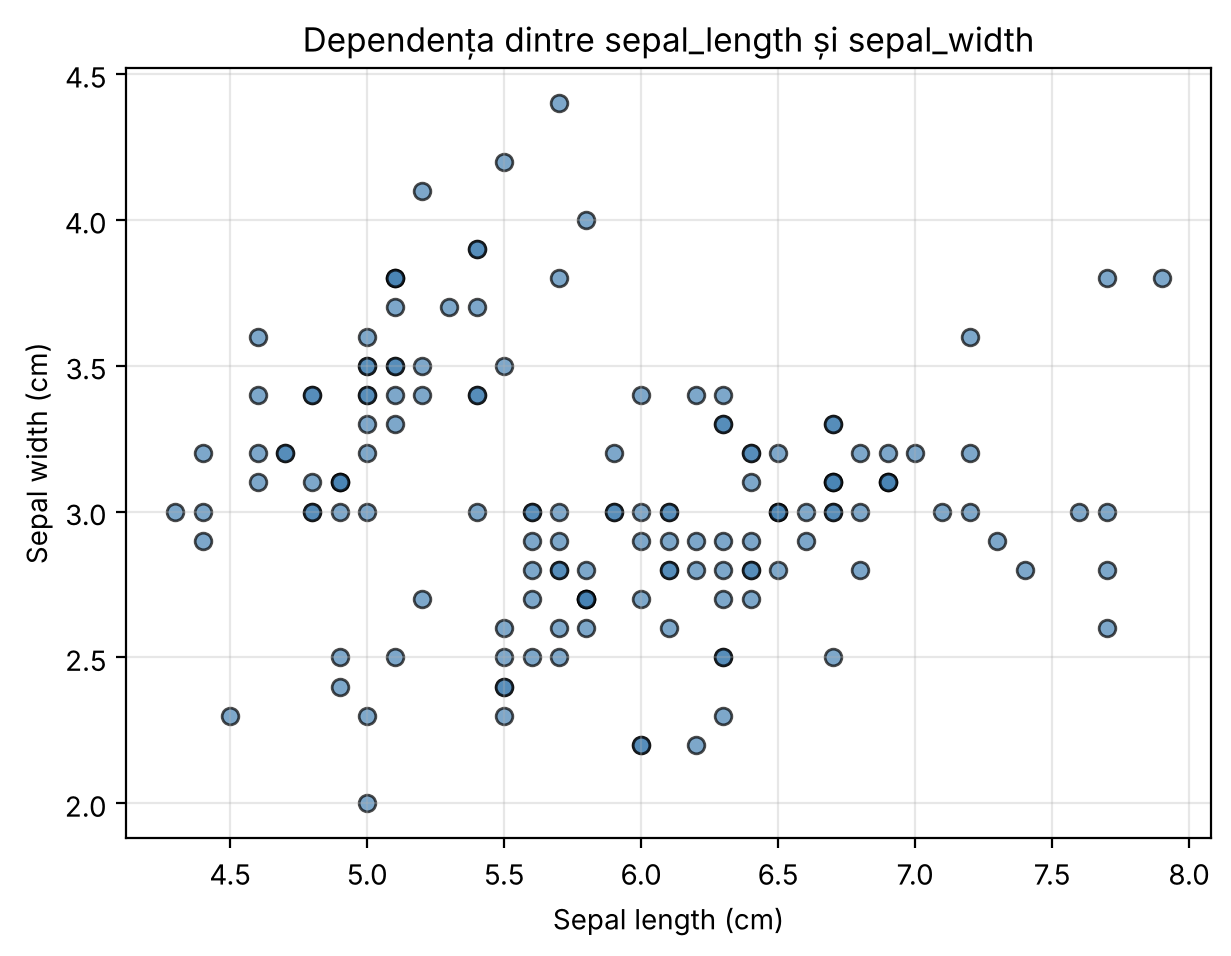

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(data['sepal_length'], data['sepal_width'], color='steelblue', alpha=0.7, edgecolor='k')
plt.xlabel('Sepal length (cm)')
plt.ylabel('Sepal width (cm)')
plt.title('Dependența dintre sepal_length și sepal_width')
plt.grid(alpha=0.3)
plt.show()

### Exercițiul 7: Numărarea frecvenței speciilor
 Folosiți o metodă specială din Pandas pentru a afla numărul exact de înregistrări pentru fiecare specie în parte din setul de date curățat.

In [8]:
data['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Exercițiul 8: Accelerarea Scikit-learn folosind Intel® Extension

Scrieți liniile de cod care trebuie executate imediat după importarea bibliotecii sklearn pentru a activa optimizarea oneDAL

In [9]:
# În Colab biblioteca trebuie instalată o singură dată:
!pip install -q scikit-learn-intelex

from sklearnex import patch_sklearn
patch_sklearn()   # trebuie apelat ÎNAINTE de importul estimatorilor din sklearn

# abia după patch se importă algoritmii, ex.:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

# pentru a reveni la implementarea standard:
# from sklearnex import unpatch_sklearn; unpatch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


### Exercițiul 9: Framework-uri în Machine Learning\

Bazându-vă pe materialele introductive, explicați de ce framework-urile sunt mai mult decât simple biblioteci și ce beneficiu material aduce optimizarea hiperparametrilor.

**Răspuns.**

O **bibliotecă** oferă un set de funcții pe care programatorul le apelează când are nevoie (ex. `numpy` pentru calcule numerice) – controlul fluxului rămâne la noi.
Un **framework** (scikit-learn, TensorFlow, PyTorch) impune o *arhitectură* și un *mod de lucru* unitar: interfețe comune (`fit` / `predict` / `transform`), conducte (`Pipeline`), instrumente de validare (`cross_val_score`, `GridSearchCV`), metrici, preprocesare, salvarea modelelor, suport pentru GPU/CPU optimizat (ex. Intel oneDAL). Framework-ul acoperă întregul ciclu de viață al modelului: date → preprocesare → antrenare → evaluare → ajustare → implementare. Astfel codul este standardizat, reproductibil, mai puțin predispus la erori și mai ușor de întreținut și extins.

**Beneficiul optimizării hiperparametrilor.** Hiperparametrii (K în KNN, adâncimea arborelui, rata de învățare, coeficientul de regularizare etc.) nu sunt învățați din date, ci aleși de noi. Căutarea sistematică a valorilor optime (Grid Search, Random Search, optimizare bayesiană) împreună cu validarea încrucișată:
- crește calitatea/precizia modelului pe date noi (generalizare mai bună);
- previne supraantrenarea și subantrenarea;
- înlocuiește alegerea „după intuiție” cu una obiectivă, măsurabilă;
- economisește timp și resurse de calcul, iar în practică se traduce în beneficiu material direct: predicții mai exacte (ex. mai puțini clienți pierduți, mai puține fraude ratate) și un model mai mic/mai rapid în producție → costuri mai mici.

### Exercițiul 10: Cerințe preliminare ale cursului
  Enumerați cel puțin trei direcții de bază  (în matematică și programare) necesare pentru parcurgerea cu succes a cursului de Machine Learning

**Răspuns.** Direcții de bază necesare:

1. **Algebra liniară** – vectori, matrici, produs scalar, înmulțirea matricilor, norme, valori și vectori proprii (date = matrici, modele = transformări liniare, PCA).
2. **Analiza matematică (calcul diferențial)** – derivate, derivate parțiale, gradient, regula lanțului – baza metodelor de optimizare (gradient descent, backpropagation).
3. **Teoria probabilităților și statistica** – distribuții, medie, dispersie, corelație, teorema lui Bayes, testarea ipotezelor, estimarea parametrilor.
4. **Programare în Python** – sintaxă, structuri de date, funcții, OOP, plus bibliotecile ecosistemului: NumPy, Pandas, Matplotlib/Seaborn, Scikit-learn.
5. (suplimentar) **Algoritmi și structuri de date / optimizare** – complexitate computațională, metode de optimizare numerică.

### Exercițiul 11: Vizualizarea avansată a distribuțiilor cu Matplotlib (Histograme)
 Folosind Matplotlib, construiți o figură cu două subgrafice (subplots) alături unul de celălalt (1 rând, 2 coloane):
 - Pe primul grafic afișați histogramei de distribuție pentru petal_length.
 - Pe al doilea grafic afișați histogramei de distribuție pentru petal_width.

 Adăugați titluri și etichete la axe pentru fiecare grafic.

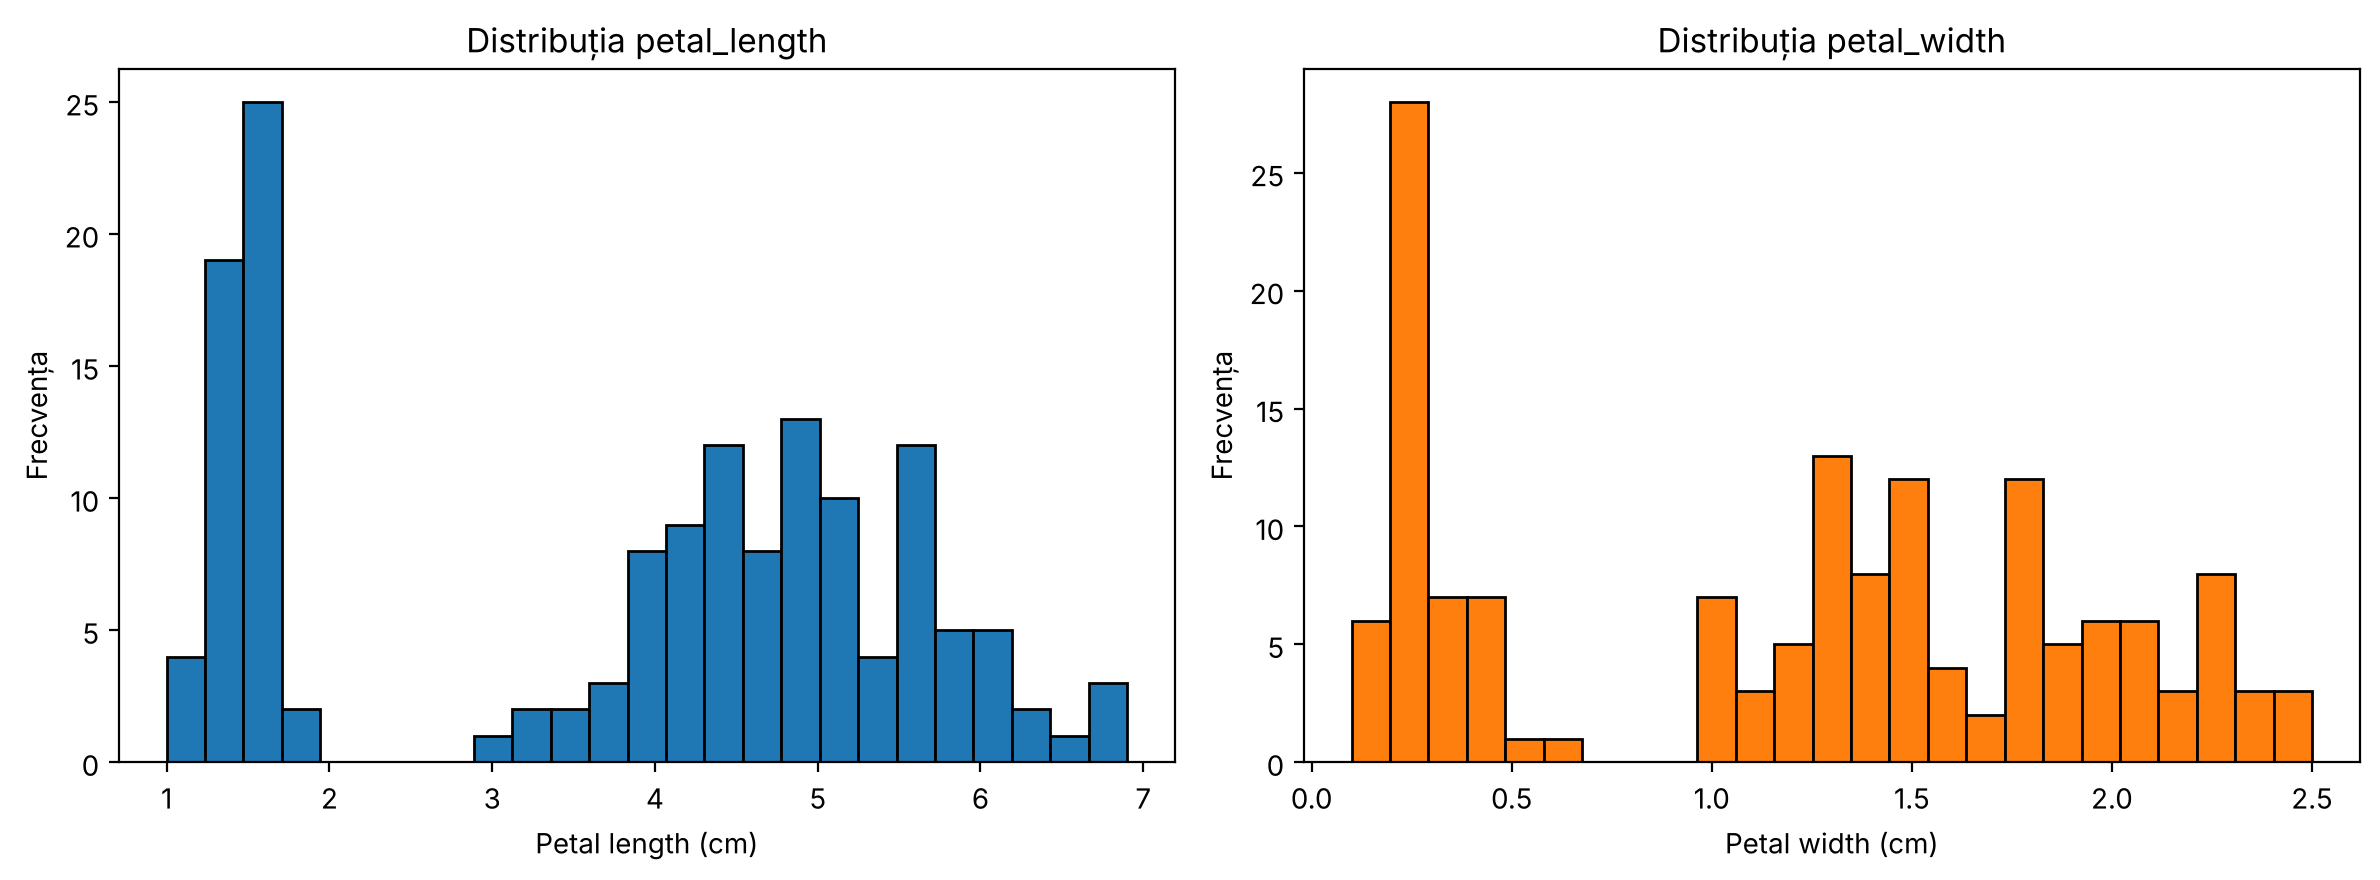

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(data['petal_length'], bins=25, color='tab:blue', edgecolor='black')
axes[0].set_title('Distribuția petal_length')
axes[0].set_xlabel('Petal length (cm)')
axes[0].set_ylabel('Frecvența')

axes[1].hist(data['petal_width'], bins=25, color='tab:orange', edgecolor='black')
axes[1].set_title('Distribuția petal_width')
axes[1].set_xlabel('Petal width (cm)')
axes[1].set_ylabel('Frecvența')

plt.tight_layout()
plt.show()

### Exercițiul 12: Explorarea datelor cu ajutorul Seaborn (Pairplot)

Importați biblioteca seaborn și construiți o matrice de grafice perechi (sns.pairplot)  pentru întregul set de date Iris, colorând punctele în funcție de specia plantei (species).

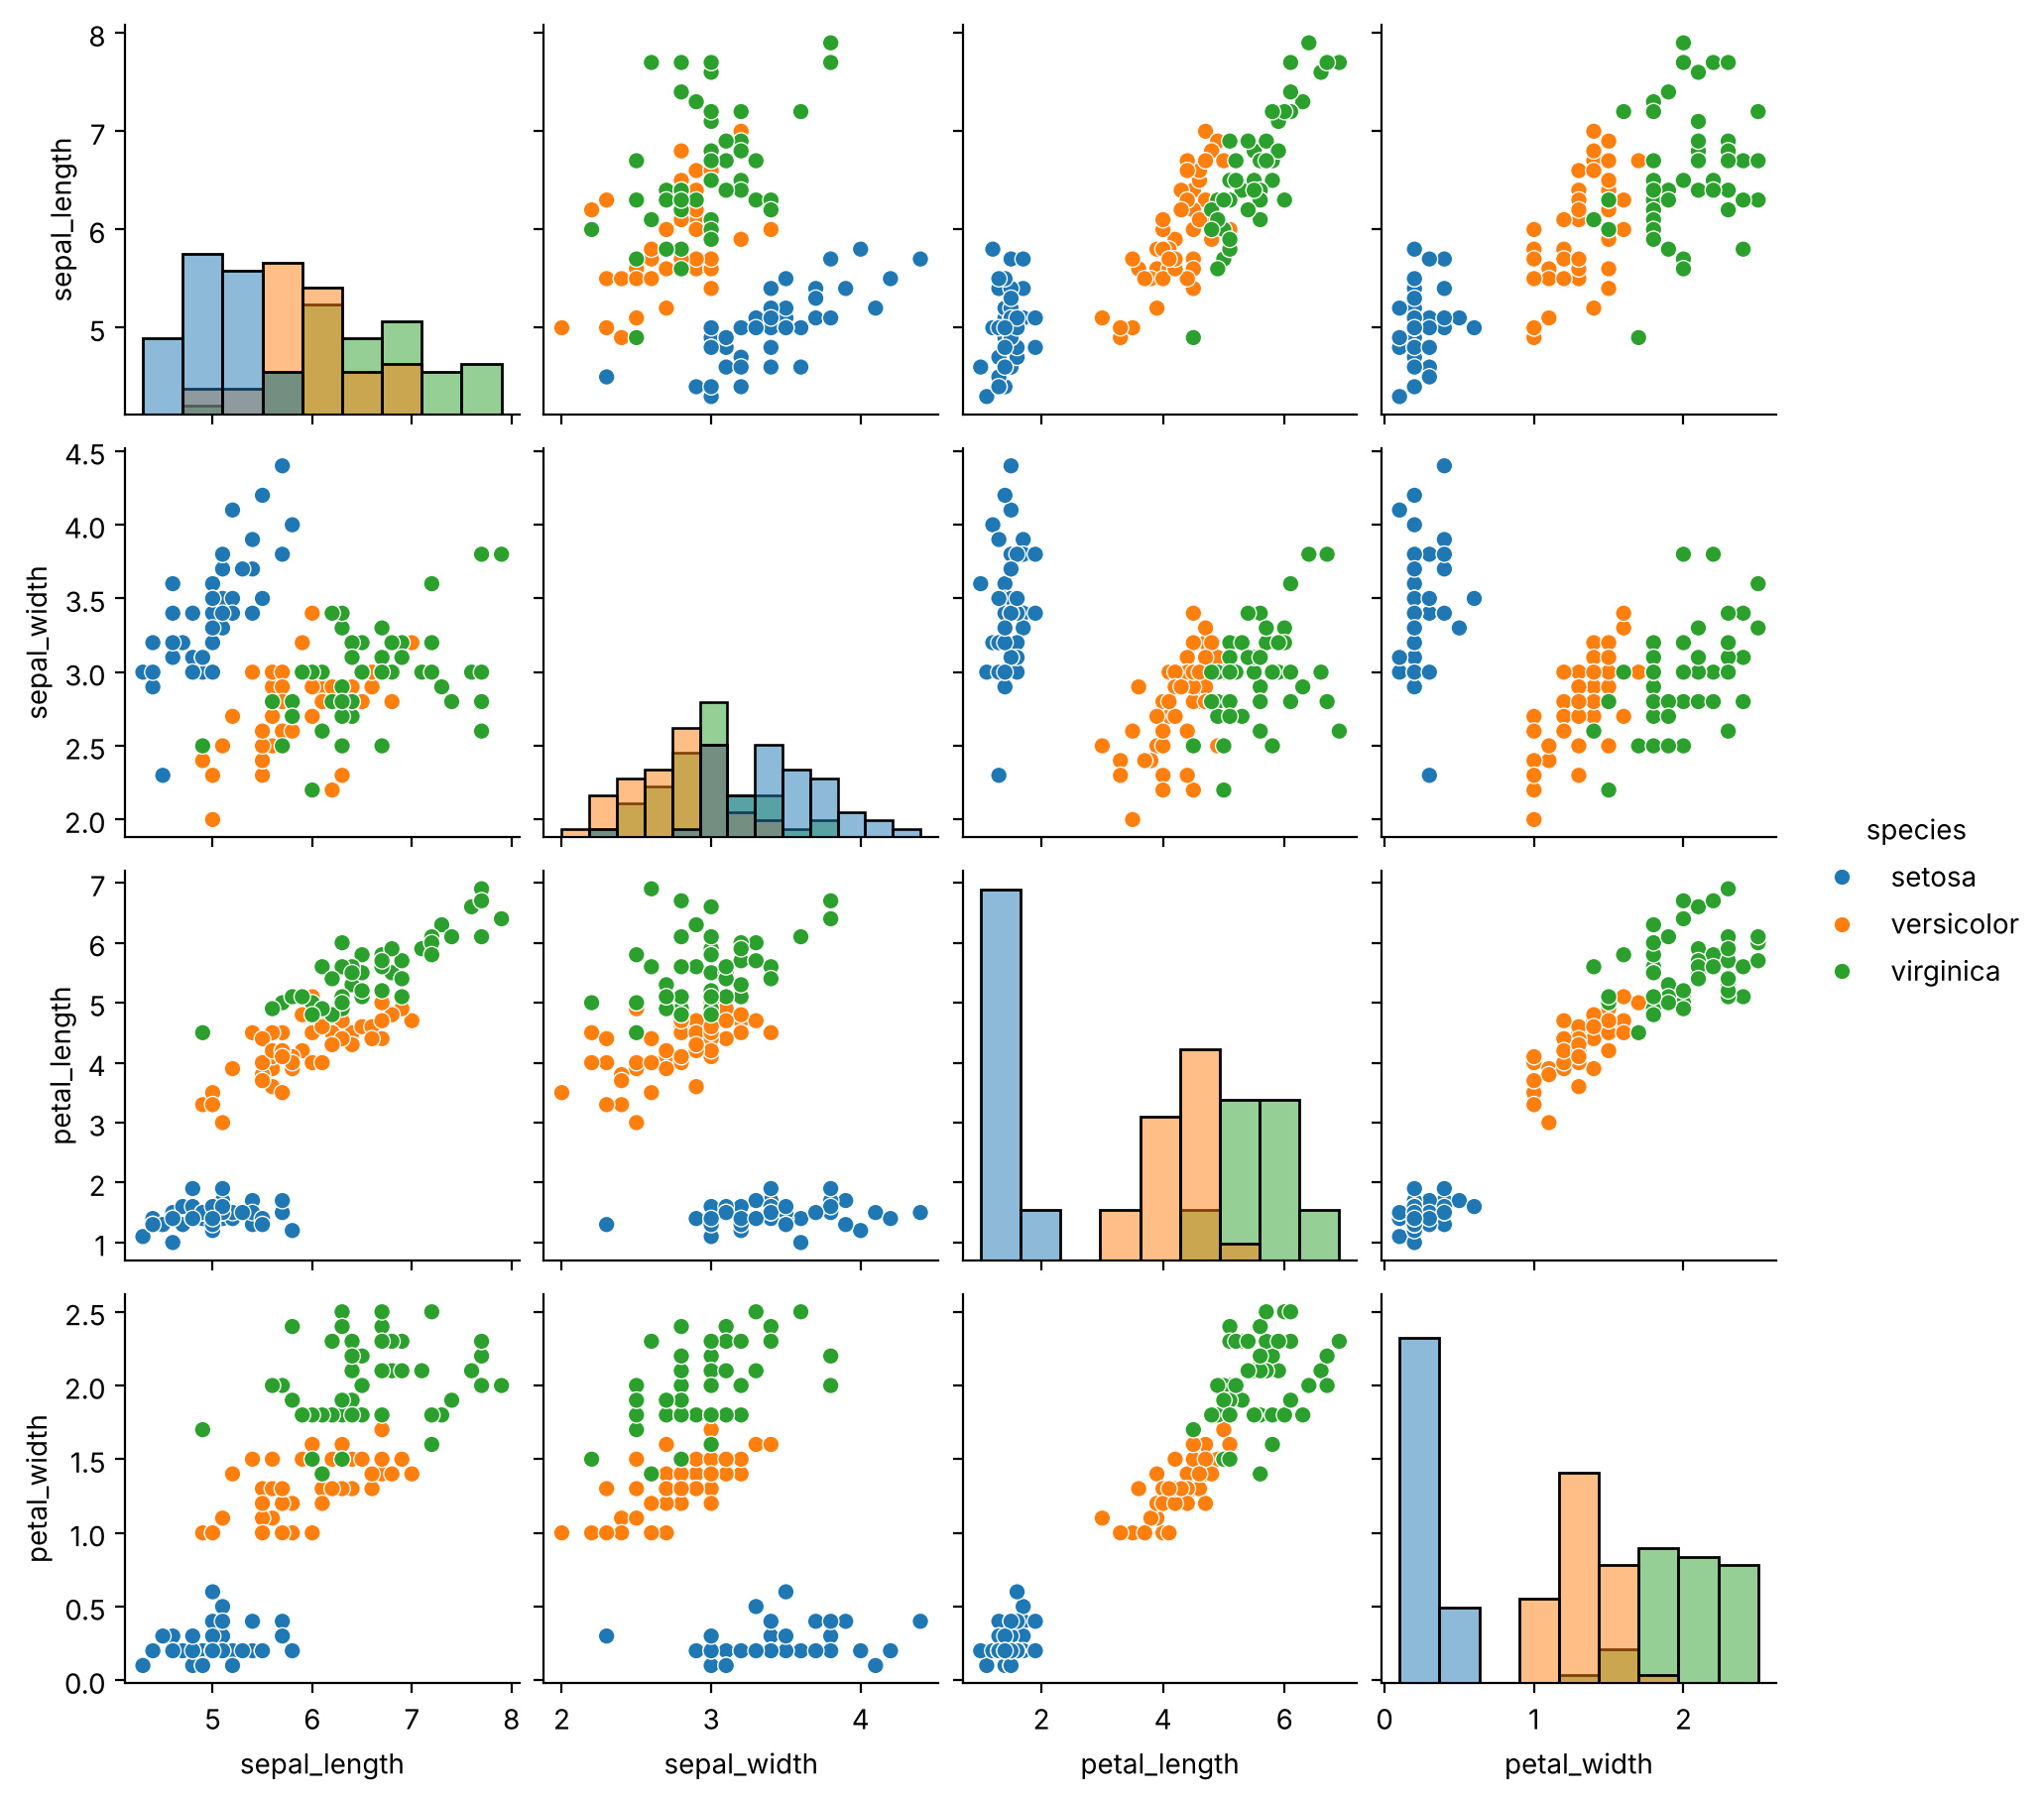

In [11]:
sns.pairplot(data, hue='species', diag_kind='hist', height=2.3)
plt.show()

### Exercițiul 13: Analiza valorilor aberante prin Boxplot (Seaborn)

Folosind biblioteca Seaborn, construiți un diagramă box-and-whisker (sns.boxplot), pentru a compara distribuția lungimii petalelor (petal_length) pentru fiecare specie în parte (species).

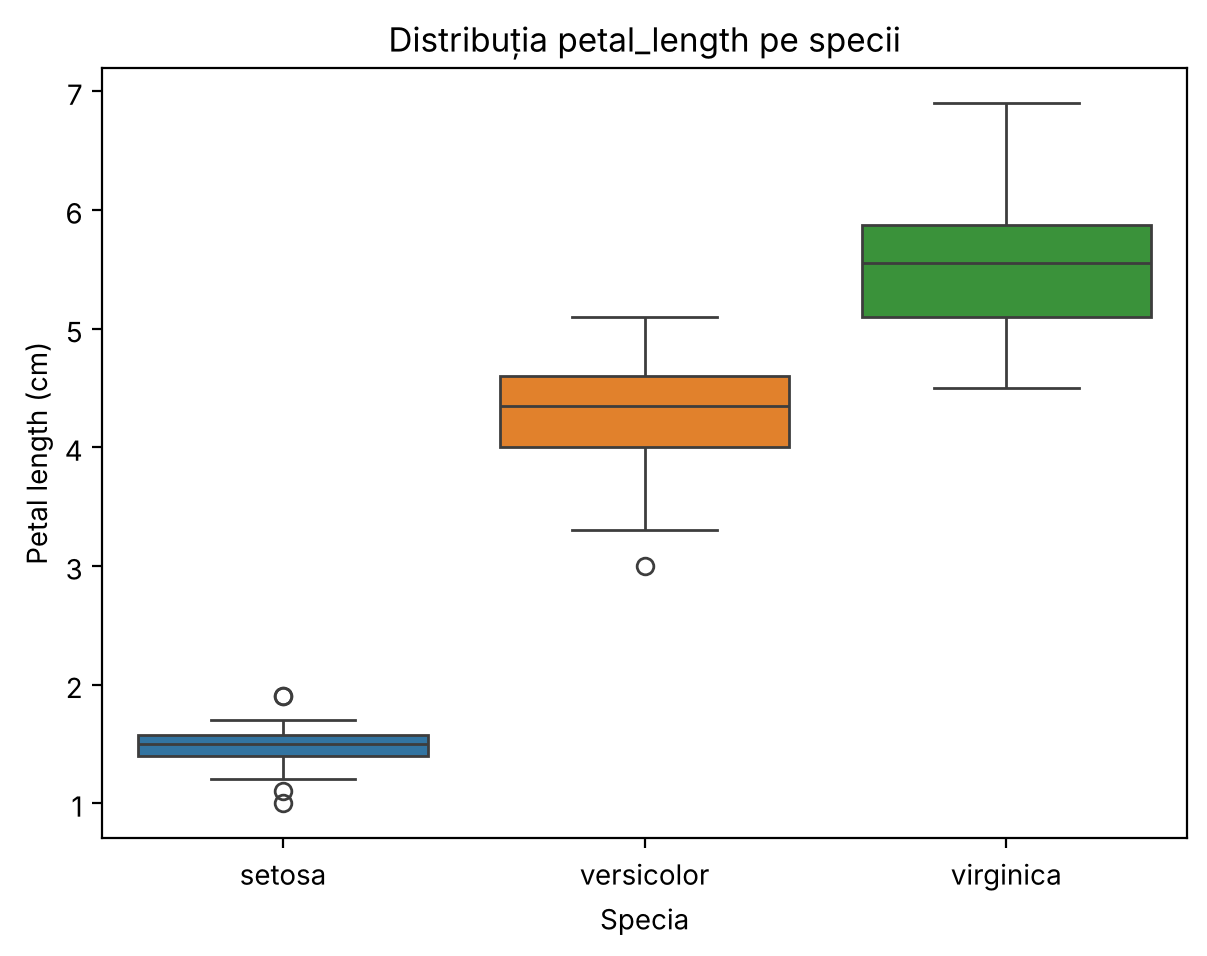

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='species', y='petal_length', hue='species', data=data, legend=False)
plt.title('Distribuția petal_length pe specii')
plt.xlabel('Specia')
plt.ylabel('Petal length (cm)')
plt.show()

### Exercițiul 14: Harta termică a corelațiilor (Seaborn Heatmap)
 Calculați matricea de corelație a caracteristicilor numerice folosind metoda corr(), iar apoi vizualizați-o sub formă de hartă termică (sns.heatmap), incluzând afișarea valorilor numerice în interiorul celulelor (annot=True).

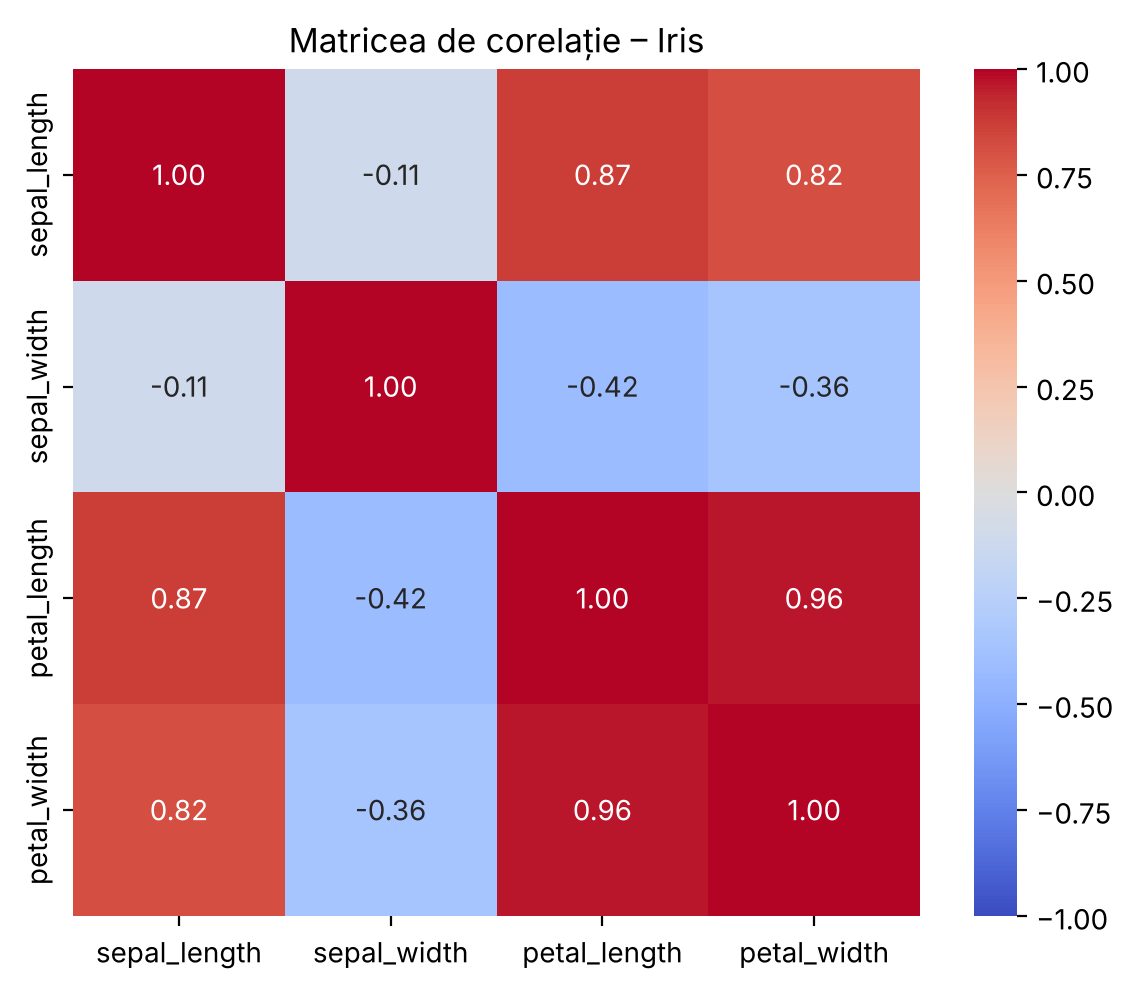

In [13]:
corr = data.select_dtypes(include='number').corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matricea de corelație – Iris')
plt.show()

**Concluzii:** `petal_length` și `petal_width` sunt foarte puternic corelate între ele (~0.96) și cu `sepal_length` (~0.87); `sepal_width` are corelație slabă negativă cu celelalte. Din pairplot și boxplot se vede că specia *setosa* este separată complet după dimensiunile petalelor, iar *versicolor* și *virginica* se suprapun parțial.